# Crop Disease Classification — PlantVillage

**Goal:** classify crop diseases from leaf images so farmers can act early with the right crop protection product.

**Summary**
- Data: PlantVillage (colour images), 54,305 images across 38 classes. Trained on a random subset of **12 classes** (18,600 images after de-duplication).
- Models compared: a small CNN trained from scratch, and three ImageNet-pretrained networks fine-tuned (MobileNetV3-Small, ResNet18, RegNetX-400MF).
- Best model for deployment: **MobileNetV3-Small**: 99.8% accuracy / 0.998 macro-F1 on the held-out test set, 6.2 MB, ~35 ms per image on CPU.
- Live demo: https://crop-disease-classifier.vercel.app

**Contents**
1. Data exploration
2. Model building (preprocessing, augmentation, training, validation)
3. Evaluation & business impact
4. Deployment (bonus)

## Setup

In [1]:
import os, time, random, hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
import torchvision
from PIL import Image
from torchvision import transforms as T
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

from data.pull_data import get_data

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# Training the 4 models took ~1-2 hours on a Colab T4 GPU. With TRAIN = False the notebook
# loads the saved weights and the training logs from that run; set TRAIN = True to retrain.
TRAIN = False
print('device:', device)

device: cpu


/Users/dhvaniraval/Downloads/crop-disease-classifier-p/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


# Part 1 — Data exploration

The dataset is downloaded with `kagglehub` (`abdallahalidev/plantvillage-dataset`). It contains three
versions of every image (colour, grayscale, segmented); only the **colour** images are used, since that is
what a farmer's phone camera produces.

In [2]:
full_dataset, class_labels = get_data()
raw_df = pd.DataFrame(full_dataset.samples, columns=['path', 'label'])
raw_df['class'] = raw_df['label'].map(lambda ix: class_labels[ix])
raw_df['crop'] = raw_df['class'].str.split('___').str[0]
raw_df['healthy'] = raw_df['class'].str.endswith('healthy')
print(f'{len(raw_df):,} images, {raw_df["class"].nunique()} classes, {raw_df["crop"].nunique()} crops')
print(f'{(~raw_df.healthy).sum():,} diseased / {raw_df.healthy.sum():,} healthy images')

Path dataset: /Users/dhvaniraval/.cache/kagglehub/datasets/abdallahalidev/plantvillage-dataset/versions/3
folders are found in: /Users/dhvaniraval/.cache/kagglehub/datasets/abdallahalidev/plantvillage-dataset/versions/3/plantvillage dataset/color
54,305 images, 38 classes, 14 crops
39,221 diseased / 15,084 healthy images


### Class distribution

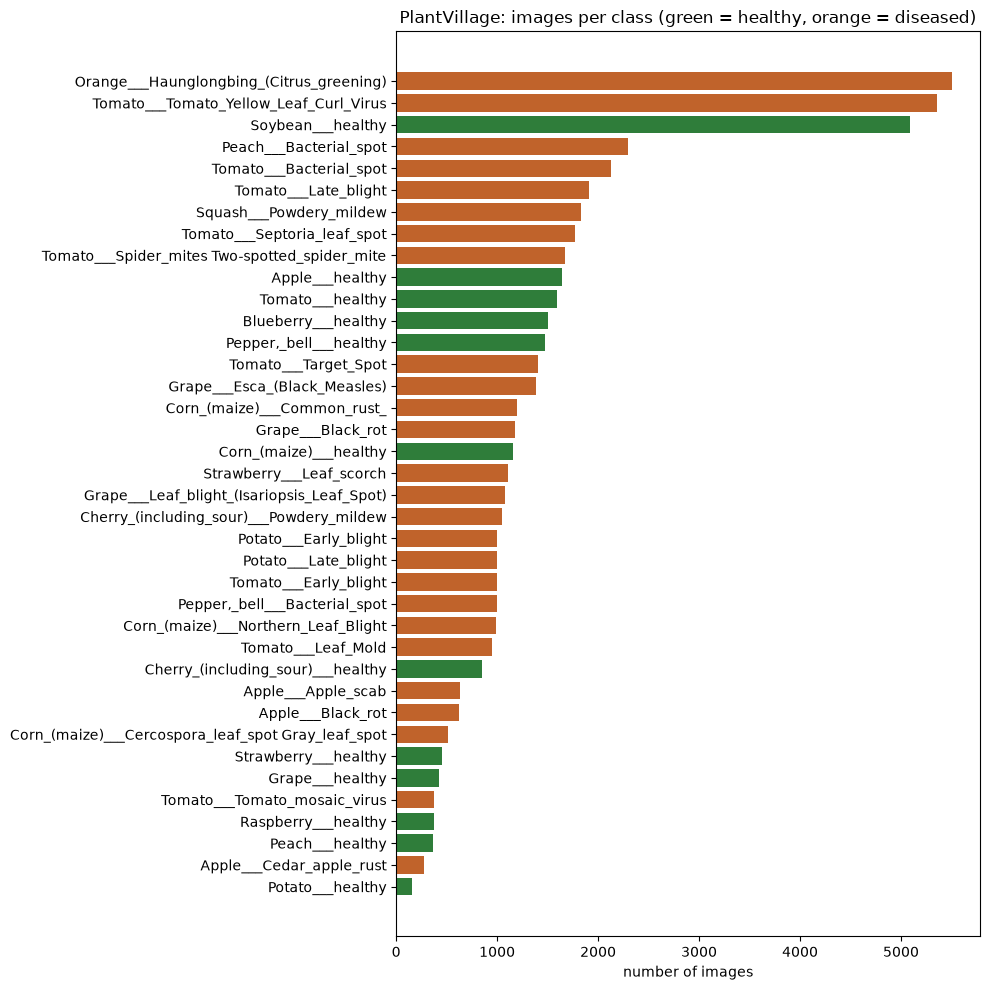

largest class: Orange___Haunglongbing_(Citrus_greening) (5,507)
smallest class: Potato___healthy (152)
imbalance ratio 36.2 : 1


In [3]:
counts = raw_df['class'].value_counts().sort_values()
fig, ax = plt.subplots(figsize=(10, 10))
colors = ['#2f7d3a' if c.endswith('healthy') else '#c0632b' for c in counts.index]
ax.barh(counts.index, counts.values, color=colors)
ax.set_xlabel('number of images'); ax.set_title('PlantVillage: images per class (green = healthy, orange = diseased)')
plt.tight_layout(); plt.show()
print(f'largest class: {counts.idxmax()} ({counts.max():,})')
print(f'smallest class: {counts.idxmin()} ({counts.min():,})')
print(f'imbalance ratio {counts.max() / counts.min():.1f} : 1')

### Sample images from 5 disease classes (5 different crops)

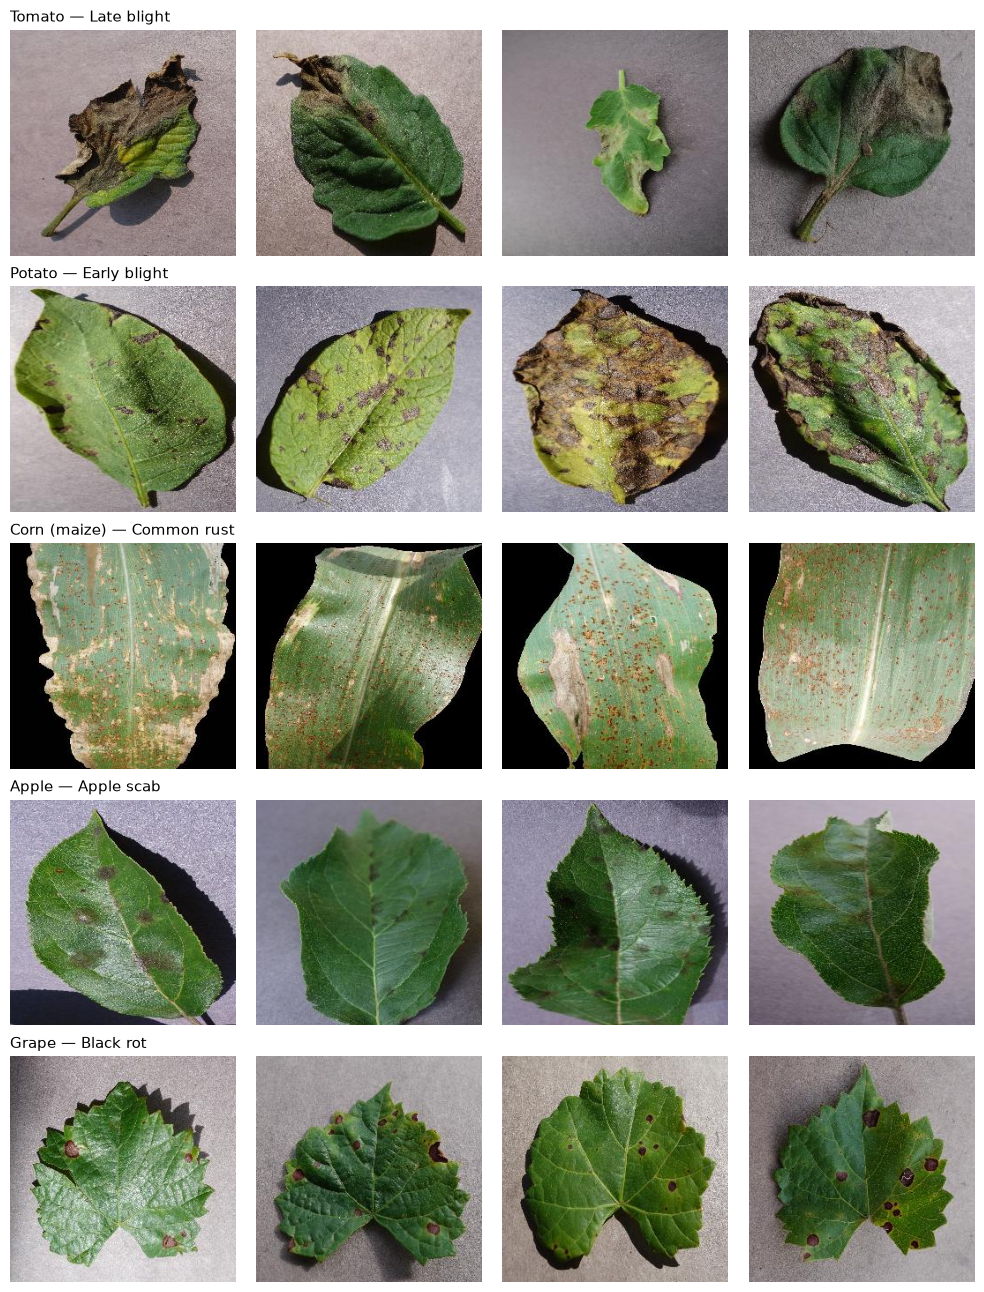

In [4]:
show_classes = ['Tomato___Late_blight', 'Potato___Early_blight', 'Corn_(maize)___Common_rust_',
                'Apple___Apple_scab', 'Grape___Black_rot']
fig, ax = plt.subplots(len(show_classes), 4, figsize=(10, 13))
for r, cls in enumerate(show_classes):
    for c, p in enumerate(raw_df[raw_df['class'] == cls].path.sample(4, random_state=1)):
        ax[r, c].imshow(Image.open(p)); ax[r, c].axis('off')
    ax[r, 0].set_title(cls.replace('___', ' — ').replace('_', ' '), loc='left', fontsize=11)
plt.tight_layout(); plt.show()

### Image properties and duplicates

In [5]:
sizes = pd.Series([Image.open(p).size for p in raw_df.path.sample(500, random_state=0)]).value_counts()
print('image sizes (sample of 500):'); print(sizes)

raw_df['hash_key'] = [hashlib.md5(open(p, 'rb').read()).hexdigest() for p in raw_df.path]
dup = raw_df[raw_df.duplicated('hash_key', keep=False)]
print(f'\n{raw_df.hash_key.duplicated().sum()} exact duplicate images in {dup.hash_key.nunique()} groups; '
      f'groups with conflicting labels: {(dup.groupby("hash_key")["class"].nunique() > 1).sum()}')

image sizes (sample of 500):
(256, 256)    500
Name: count, dtype: int64



21 exact duplicate images in 21 groups; groups with conflicting labels: 0


### Background check — could the model cheat?

PlantVillage photos were taken in a lab, one leaf per photo on a plain background. If the background differs
between classes, a model can learn the background instead of the disease. Below: the average colour of a
12-pixel border around each image (the border is mostly background), for 50 images per class.

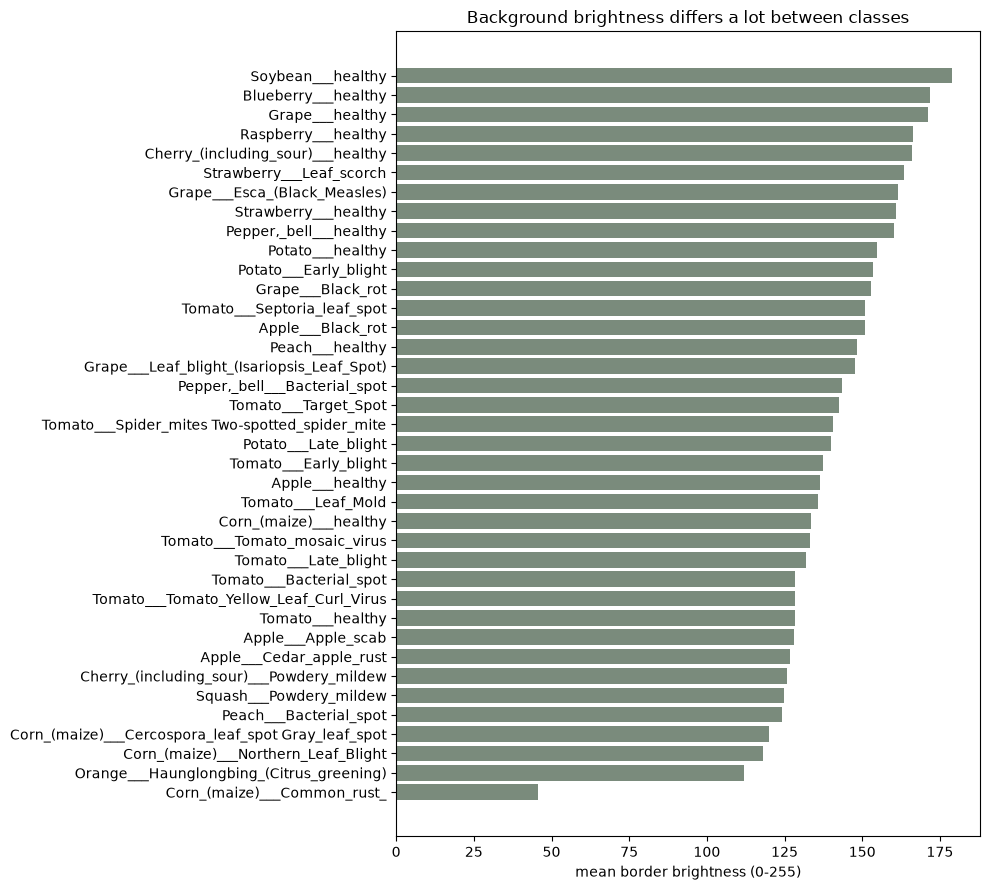

darkest: Corn_(maize)___Common_rust_ (46), brightest: Soybean___healthy (179)


In [6]:
def border_mean(p, b=12):
    a = np.asarray(Image.open(p).convert('RGB'), dtype=float)
    m = np.ones(a.shape[:2], bool); m[b:-b, b:-b] = False
    return a[m].mean(0)

s = raw_df.groupby('class').sample(50, random_state=0)
bm = pd.DataFrame([border_mean(p) for p in s.path], columns=['R', 'G', 'B'])
bm['class'] = s['class'].values
bm['brightness'] = bm[['R', 'G', 'B']].mean(axis=1)
by_class = bm.groupby('class')['brightness'].mean().sort_values()

fig, ax = plt.subplots(figsize=(10, 9))
ax.barh(by_class.index, by_class.values, color='#7a8b7c')
ax.set_xlabel('mean border brightness (0-255)'); ax.set_title('Background brightness differs a lot between classes')
plt.tight_layout(); plt.show()
print(f'darkest: {by_class.idxmin()} ({by_class.min():.0f}), brightest: {by_class.idxmax()} ({by_class.max():.0f})')

### Key insights

1. **Strong class imbalance (36 : 1).** Orange citrus greening has 5,507 images while Potato healthy has
   only 152. A model can score high accuracy by favouring the big classes, so we use **class-weighted loss**,
   a **stratified split**, and report **macro-F1** (every class counts equally) alongside accuracy.
2. **Clean but lab-like images.** Every image is 256×256, one leaf, centred, on a plain background, and labels
   are reliable (the 21 duplicate pairs all share the same label, so we simply drop the extra copies).
   This makes the task much easier than real field photos with soil, multiple leaves and sunlight.
3. **Background is a shortcut risk.** Average background brightness ranges from 46 to 179 depending on the
   class, because each class was photographed in different sessions. Corn common rust stands out: its leaves
   were shot on a black background. Part of the very high
   accuracy below may come from these cues, so performance on real farm photos must be checked before launch.

# Part 2 — Model building

### Preprocessing
1. Remove the exact duplicates found above.
2. Pick **12 random classes** (seed 42) to keep training time manageable.
3. Stratified split **70% train / ~20% validation / ~10% test**, done *before* augmentation so no augmented
   copy of a test image can leak into training.

18,600 images in 12 classes -> train 13,020 / val 3,627 / test 1,953


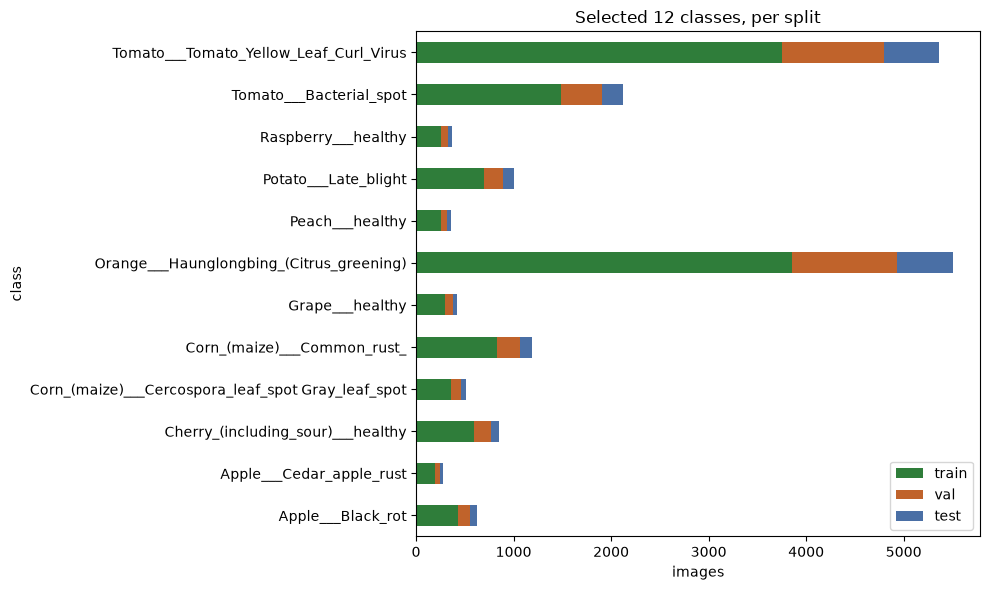

In [7]:
df = raw_df.drop_duplicates('hash_key', keep='first').reset_index(drop=True)

random.seed(SEED)
selected = sorted(random.sample(sorted(df['class'].unique()), 12))
df12 = df[df['class'].isin(selected)].reset_index(drop=True)
df12['label'] = df12['class'].map({c: i for i, c in enumerate(selected)})
K = len(selected)

train_df, temp = train_test_split(df12, test_size=0.30, stratify=df12.label, random_state=SEED)
val_df, test_df = train_test_split(temp, test_size=0.35, stratify=temp.label, random_state=SEED)
test_df = test_df.reset_index(drop=True)
print(f'{len(df12):,} images in 12 classes -> train {len(train_df):,} / val {len(val_df):,} / test {len(test_df):,}')

split_counts = pd.DataFrame({'train': train_df['class'].value_counts(), 'val': val_df['class'].value_counts(),
                             'test': test_df['class'].value_counts()}).loc[selected]
split_counts.plot.barh(stacked=True, figsize=(10, 6), color=['#2f7d3a', '#c0632b', '#4a6fa5'])
plt.xlabel('images'); plt.title('Selected 12 classes, per split'); plt.tight_layout(); plt.show()

### Augmentation
Training images get random **zoom/crop** (`RandomResizedCrop`, 70–100% of the image), horizontal and vertical
**flips**, and **rotation** up to 30°. Leaves have no natural "up", so all of these are realistic.
Validation and test images are only resized. All images are normalised with ImageNet statistics, which the
pretrained models expect.

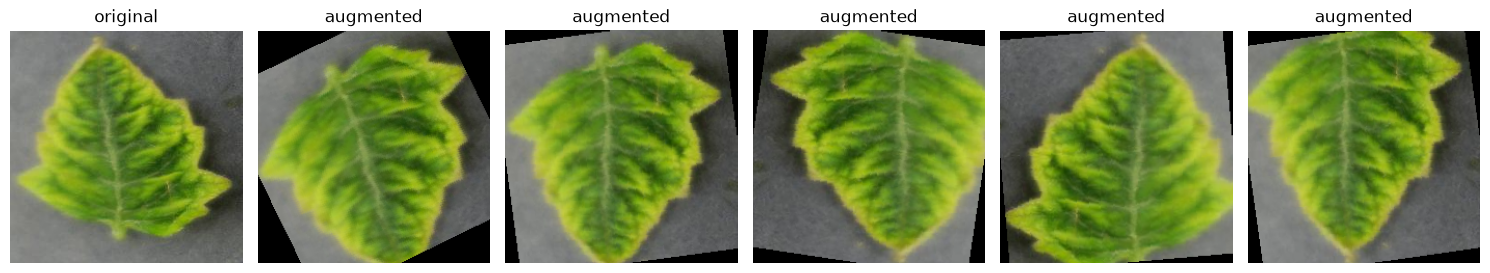

In [8]:
mean, std = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
aug_train = T.Compose([T.RandomResizedCrop(224, scale=(0.7, 1.0)), T.RandomHorizontalFlip(),
                       T.RandomVerticalFlip(), T.RandomRotation(30), T.ToTensor(), T.Normalize(mean, std)])
aug_eval = T.Compose([T.Resize((224, 224)), T.ToTensor(), T.Normalize(mean, std)])

def denorm(x):
    return (x.permute(1, 2, 0).numpy() * std + mean).clip(0, 1)

img = Image.open(train_df.path.iloc[0]).convert('RGB')
fig, ax = plt.subplots(1, 6, figsize=(15, 3))
ax[0].imshow(img); ax[0].set_title('original')
for a in ax[1:]:
    a.imshow(denorm(aug_train(img))); a.set_title('augmented')
for a in ax: a.axis('off')
plt.tight_layout(); plt.show()

### Data loaders
Only the training loader is shuffled. Validation and test loaders keep their order and keep every image,
so prediction *i* always belongs to row *i* of `test_df` (needed for the image grids in Part 3).

In [9]:
class PlantDataset(Dataset):
    def __init__(self, df, transform):
        self.paths, self.labels, self.transform = df['path'].tolist(), df['label'].tolist(), transform
    def __len__(self):
        return len(self.paths)
    def __getitem__(self, i):
        return self.transform(Image.open(self.paths[i]).convert('RGB')), self.labels[i]

BATCH_SIZE = 32
NUM_WORKERS = min(4, os.cpu_count() or 2) if device.type == 'cuda' else 0
loader = lambda d, tf, train: DataLoader(PlantDataset(d, tf), batch_size=BATCH_SIZE, shuffle=train,
                                         drop_last=train, num_workers=NUM_WORKERS,
                                         pin_memory=device.type == 'cuda')
train_loader = loader(train_df, aug_train, True)
val_loader = loader(val_df, aug_eval, False)
test_loader = loader(test_df, aug_eval, False)
print(len(train_loader), len(val_loader), len(test_loader), 'batches')

406 114 62 batches


### Models
| Model | Type | Why try it |
|---|---|---|
| `small_cnn` | 4 conv blocks, trained from scratch | Baseline: how far do we get without pretraining? |
| `mobilenet_v3_small` | Pretrained (ImageNet), fine-tuned | Built for phones: small and fast |
| `resnet18` | Pretrained, fine-tuned | Classic, widely used reference |
| `regnet_x_400mf` | Pretrained, fine-tuned | Efficient mid-size network |

For the pretrained models only the last layer is replaced (1000 ImageNet classes → 12), then the whole network
is fine-tuned.

In [10]:
class SmallCNN(nn.Module):
    def __init__(self, k):
        super().__init__()
        block = lambda i, o: nn.Sequential(nn.Conv2d(i, o, 3, padding=1, bias=False), nn.BatchNorm2d(o),
                                           nn.ReLU(inplace=True), nn.MaxPool2d(2))
        self.features = nn.Sequential(block(3, 32), block(32, 64), block(64, 128), block(128, 256))
        self.head = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Dropout(0.3), nn.Linear(256, k))
    def forward(self, x):
        return self.head(self.features(x))

def build_model(name, pretrained=True):
    tv = torchvision.models
    if name == 'small_cnn':
        return SmallCNN(K)
    if name == 'mobilenet_v3_small':
        m = tv.mobilenet_v3_small(weights=tv.MobileNet_V3_Small_Weights.DEFAULT if pretrained else None)
        m.classifier[3] = nn.Linear(m.classifier[3].in_features, K); return m
    if name == 'resnet18':
        m = tv.resnet18(weights=tv.ResNet18_Weights.DEFAULT if pretrained else None)
        m.fc = nn.Linear(m.fc.in_features, K); return m
    if name == 'regnet_x_400mf':
        m = tv.regnet_x_400mf(weights=tv.RegNet_X_400MF_Weights.DEFAULT if pretrained else None)
        m.fc = nn.Linear(m.fc.in_features, K); return m

MODEL_NAMES = ['small_cnn', 'mobilenet_v3_small', 'resnet18', 'regnet_x_400mf']

### Training and validation
- **Loss:** cross-entropy with class weights (square root of inverse class frequency, from the training set
  only), so rare classes are not ignored without over-correcting.
- **Optimiser:** AdamW with cosine learning-rate decay.
- **Validation:** after every epoch we compute validation macro-F1, keep the best weights, and **stop early**
  if it does not improve for 3 epochs.

In [11]:
n = train_df['label'].value_counts().sort_index().values
w = (len(train_df) / (K * n)) ** 0.5
criterion = nn.CrossEntropyLoss(weight=torch.tensor(w, dtype=torch.float32, device=device))
use_amp = device.type == 'cuda'

EPOCHS = {'small_cnn': 15, 'mobilenet_v3_small': 10, 'resnet18': 10, 'regnet_x_400mf': 10}
LR = {'small_cnn': 2e-3, 'mobilenet_v3_small': 5e-4, 'resnet18': 5e-4, 'regnet_x_400mf': 5e-4}
PATIENCE, MIN_DELTA = 3, 0.001

def run_epoch(model, loader, optimizer=None, scaler=None):
    train = optimizer is not None
    model.train(train)
    loss_sum, preds, labels = 0.0, [], []
    with torch.set_grad_enabled(train):
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=use_amp):
                out = model(x); loss = criterion(out, y)
            if train:
                optimizer.zero_grad(set_to_none=True)
                if scaler: scaler.scale(loss).backward(); scaler.step(optimizer); scaler.update()
                else: loss.backward(); optimizer.step()
            loss_sum += loss.item() * len(y)
            preds.append(out.argmax(1).cpu()); labels.append(y.cpu())
    p, l = torch.cat(preds).numpy(), torch.cat(labels).numpy()
    return loss_sum / len(l), accuracy_score(l, p), f1_score(l, p, average='macro')

def fit(name):
    model = build_model(name).to(device)
    opt = torch.optim.AdamW(model.parameters(), lr=LR[name], weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=EPOCHS[name])
    scaler = torch.amp.GradScaler('cuda') if use_amp else None
    hist = {'train_loss': [], 'val_loss': [], 'val_f1': []}
    best_f1, best_state, wait = -1, None, 0
    for ep in range(EPOCHS[name]):
        t0 = time.time()
        tl, ta, _ = run_epoch(model, train_loader, opt, scaler)
        vl, va, vf1 = run_epoch(model, val_loader)
        sched.step()
        hist['train_loss'].append(tl); hist['val_loss'].append(vl); hist['val_f1'].append(vf1)
        if vf1 > best_f1 + MIN_DELTA:
            best_f1, wait = vf1, 0
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        else:
            wait += 1
        print(f'{name} {ep + 1}/{EPOCHS[name]} | train loss {tl:.3f} acc {ta:.3f} | '
              f'val loss {vl:.3f} acc {va:.3f} F1 {vf1:.3f} | {time.time() - t0:.0f}s')
        if wait >= PATIENCE:
            print(f'early stop at epoch {ep + 1}, best val F1 {best_f1:.3f}'); break
    model.load_state_dict(best_state)
    torch.save(best_state, f'{name}.pt')
    return model, hist

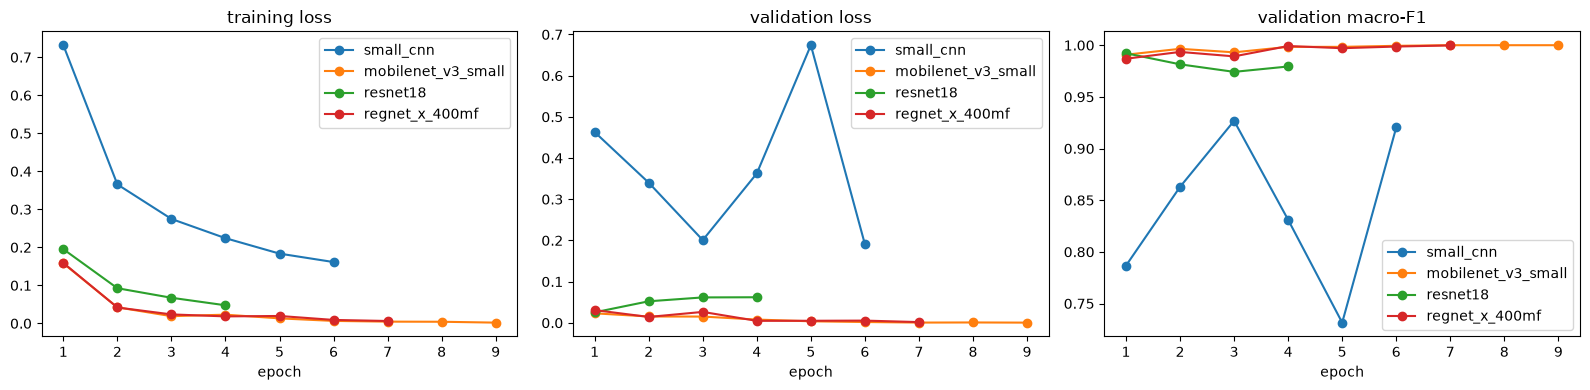

In [12]:
# Training logs recorded on the Colab T4 GPU run (used when TRAIN = False)
COLAB_HISTORIES = {
 'small_cnn': {'train_loss': [0.7317, 0.3655, 0.2747, 0.2241, 0.1835, 0.1613],
               'val_loss': [0.4630, 0.3401, 0.2007, 0.3626, 0.6739, 0.1906],
               'val_f1': [0.7867, 0.8629, 0.9268, 0.8310, 0.7315, 0.9204]},
 'mobilenet_v3_small': {'train_loss': [0.1578, 0.0422, 0.0190, 0.0229, 0.0132, 0.0065, 0.0046, 0.0043, 0.0020],
               'val_loss': [0.0230, 0.0153, 0.0151, 0.0078, 0.0036, 0.0019, 0.0005, 0.0008, 0.0004],
               'val_f1': [0.9908, 0.9965, 0.9931, 0.9984, 0.9984, 0.9994, 1.0, 1.0, 1.0]},
 'resnet18': {'train_loss': [0.1952, 0.0925, 0.0674, 0.0476],
               'val_loss': [0.0254, 0.0522, 0.0616, 0.0620],
               'val_f1': [0.9922, 0.9815, 0.9742, 0.9794]},
 'regnet_x_400mf': {'train_loss': [0.1590, 0.0418, 0.0236, 0.0184, 0.0195, 0.0091, 0.0063],
               'val_loss': [0.0308, 0.0142, 0.0264, 0.0047, 0.0049, 0.0053, 0.0017],
               'val_f1': [0.9869, 0.9935, 0.9892, 0.9992, 0.9971, 0.9987, 0.9998]},
}

if TRAIN:
    histories = {}
    for name in MODEL_NAMES:
        _, histories[name] = fit(name)
else:
    histories = COLAB_HISTORIES

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for name, h in histories.items():
    ep = range(1, len(h['val_f1']) + 1)
    ax[0].plot(ep, h['train_loss'], marker='o', label=name)
    ax[1].plot(ep, h['val_loss'], marker='o', label=name)
    ax[2].plot(ep, h['val_f1'], marker='o', label=name)
for a, t in zip(ax, ['training loss', 'validation loss', 'validation macro-F1']):
    a.set_xlabel('epoch'); a.set_title(t); a.legend()
plt.tight_layout(); plt.show()

**Reading the curves**
- The pretrained models reach >0.99 validation F1 after the **first** epoch: ImageNet features transfer very
  well to leaf images.
- The small CNN learns more slowly and its validation loss jumps around (epochs 4–5), a sign that it is less
  stable without pretrained features.
- ResNet18 peaks at epoch 1 and then gets worse on validation while training loss keeps falling, which is
  overfitting. Early stopping keeps its epoch-1 weights.

# Part 3 — Evaluation & business impact

### Model comparison on the held-out test set
Test-set results for all four models, measured on Colab. CPU latency is the median time for one 224×224
image on a single CPU thread (batch size 1), which approximates a low-end phone better than a GPU number.

In [13]:
results = pd.DataFrame({
    'model': MODEL_NAMES,
    'test_accuracy': [0.936, 0.998, 0.992, 0.998],
    'test_macro_f1': [0.927, 0.998, 0.987, 0.998],
    'params_M': [0.39, 1.53, 11.18, 5.10],
    'size_MB': [1.58, 6.25, 44.81, 20.69],
    'cpu_latency_ms': [83.6, 35.3, 55.9, 25.0],
}).set_index('model')
results

,test_accuracy,test_macro_f1,params_M,size_MB,cpu_latency_ms
model,,,,,
small_cnn,0.936,0.927,0.39,1.58,83.6
mobilenet_v3_small,0.998,0.998,1.53,6.25,35.3
resnet18,0.992,0.987,11.18,44.81,55.9
regnet_x_400mf,0.998,0.998,5.10,20.69,25.0


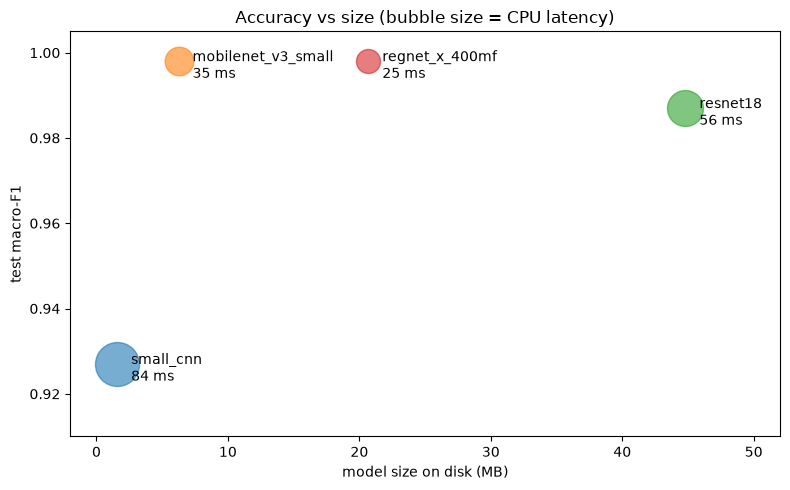

In [14]:
fig, ax = plt.subplots(figsize=(8, 5))
for name, r in results.iterrows():
    ax.scatter(r.size_MB, r.test_macro_f1, s=r.cpu_latency_ms * 12, alpha=0.6)
    ax.annotate(f'{name}\n{r.cpu_latency_ms:.0f} ms', (r.size_MB, r.test_macro_f1),
                textcoords='offset points', xytext=(10, -12))
ax.set_xlabel('model size on disk (MB)'); ax.set_xlim(-2, 52); ax.set_ylabel('test macro-F1')
ax.set_title('Accuracy vs size (bubble size = CPU latency)'); ax.set_ylim(0.91, 1.005)
plt.tight_layout(); plt.show()

### Detailed evaluation of the chosen model: MobileNetV3-Small
Re-evaluated here on **all 1,953 test images** from the saved weights.

In [15]:
name = 'mobilenet_v3_small'
model = build_model(name, pretrained=False)
model.load_state_dict(torch.load(f'{name}.pt', map_location='cpu'))
model = model.to(device).eval()

@torch.no_grad()
def predict(model, loader):
    probs, labels = [], []
    for x, y in loader:
        probs.append(torch.softmax(model(x.to(device)).float(), 1).cpu()); labels.append(y)
    return torch.cat(probs).numpy(), torch.cat(labels).numpy()

probs, labels = predict(model, test_loader)
preds, conf = probs.argmax(1), probs.max(1)
assert (labels == test_df['label'].values).all()   # predictions line up with test_df rows
print(f'test images: {len(labels)} | accuracy {accuracy_score(labels, preds):.4f} | '
      f'macro-F1 {f1_score(labels, preds, average="macro"):.4f} | wrong: {(preds != labels).sum()}')

test images: 1953 | accuracy 0.9985 | macro-F1 0.9984 | wrong: 3


In [16]:
SHORT = {'Apple___Black_rot': 'Apple: Black rot', 'Apple___Cedar_apple_rust': 'Apple: Cedar rust',
         'Cherry_(including_sour)___healthy': 'Cherry: healthy',
         'Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot': 'Corn: Gray leaf spot',
         'Corn_(maize)___Common_rust_': 'Corn: Common rust', 'Grape___healthy': 'Grape: healthy',
         'Orange___Haunglongbing_(Citrus_greening)': 'Orange: Citrus greening', 'Peach___healthy': 'Peach: healthy',
         'Potato___Late_blight': 'Potato: Late blight', 'Raspberry___healthy': 'Raspberry: healthy',
         'Tomato___Bacterial_spot': 'Tomato: Bacterial spot',
         'Tomato___Tomato_Yellow_Leaf_Curl_Virus': 'Tomato: Yellow leaf curl'}
short = [SHORT[c] for c in selected]
print(classification_report(labels, preds, target_names=short, digits=3))

                          precision    recall  f1-score   support

        Apple: Black rot      1.000     1.000     1.000        65
       Apple: Cedar rust      1.000     1.000     1.000        29
         Cherry: healthy      1.000     1.000     1.000        90
    Corn: Gray leaf spot      0.982     1.000     0.991        54
       Corn: Common rust      1.000     0.992     0.996       125
          Grape: healthy      1.000     1.000     1.000        44
 Orange: Citrus greening      1.000     1.000     1.000       578
          Peach: healthy      1.000     1.000     1.000        38
     Potato: Late blight      1.000     1.000     1.000       105
      Raspberry: healthy      1.000     1.000     1.000        39
  Tomato: Bacterial spot      0.991     1.000     0.996       223
Tomato: Yellow leaf curl      1.000     0.996     0.998       563

                accuracy                          0.998      1953
               macro avg      0.998     0.999     0.998      1953
        

### Confusion matrix

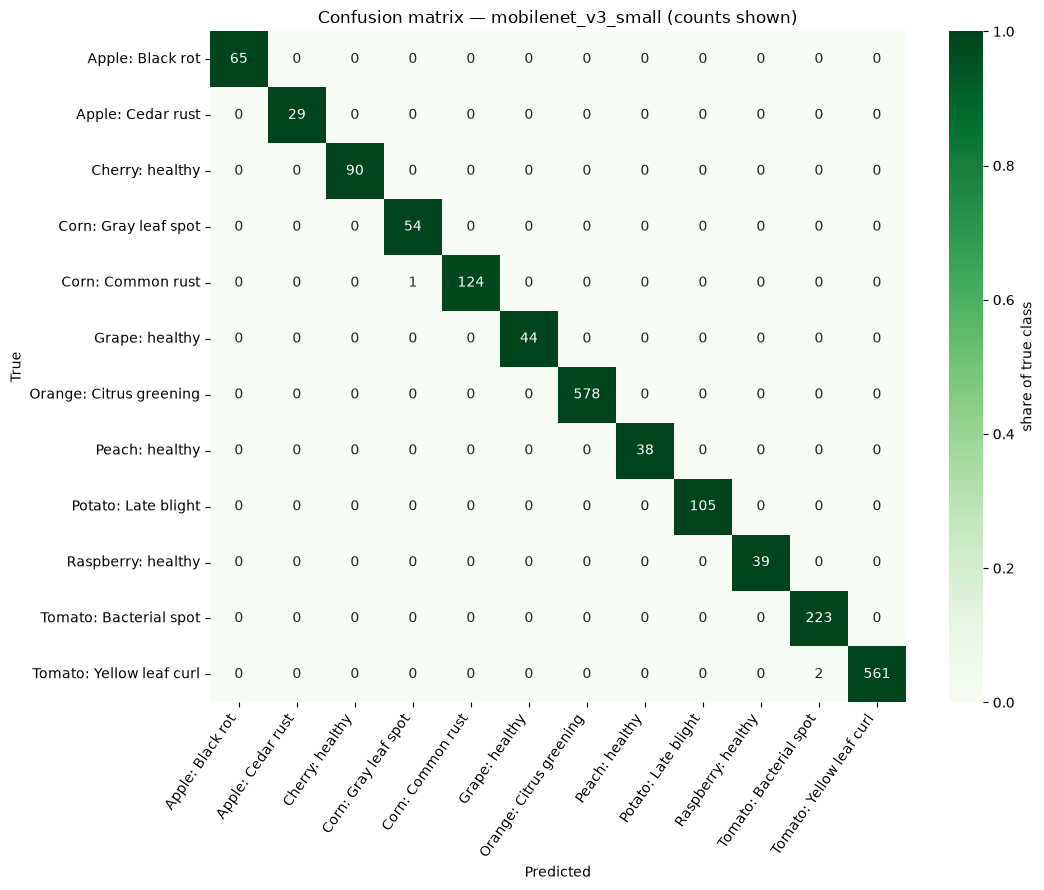

Confusions (count: true -> predicted):
  2: Tomato: Yellow leaf curl -> Tomato: Bacterial spot
  1: Corn: Common rust -> Corn: Gray leaf spot


In [17]:
cm = confusion_matrix(labels, preds, labels=range(K))
cm_norm = cm / cm.sum(axis=1, keepdims=True)
plt.figure(figsize=(11, 9))
sns.heatmap(cm_norm, annot=cm, fmt='d', cmap='Greens', xticklabels=short, yticklabels=short,
            cbar_kws={'label': 'share of true class'})
plt.xlabel('Predicted'); plt.ylabel('True'); plt.title(f'Confusion matrix — {name} (counts shown)')
plt.xticks(rotation=55, ha='right'); plt.tight_layout(); plt.show()

off = sorted([(cm[i, j], short[i], short[j]) for i in range(K) for j in range(K) if i != j and cm[i, j]], reverse=True)
print('Confusions (count: true -> predicted):')
for c, t, p in off: print(f'  {c}: {t} -> {p}')

### 5 correct and 5 incorrect predictions

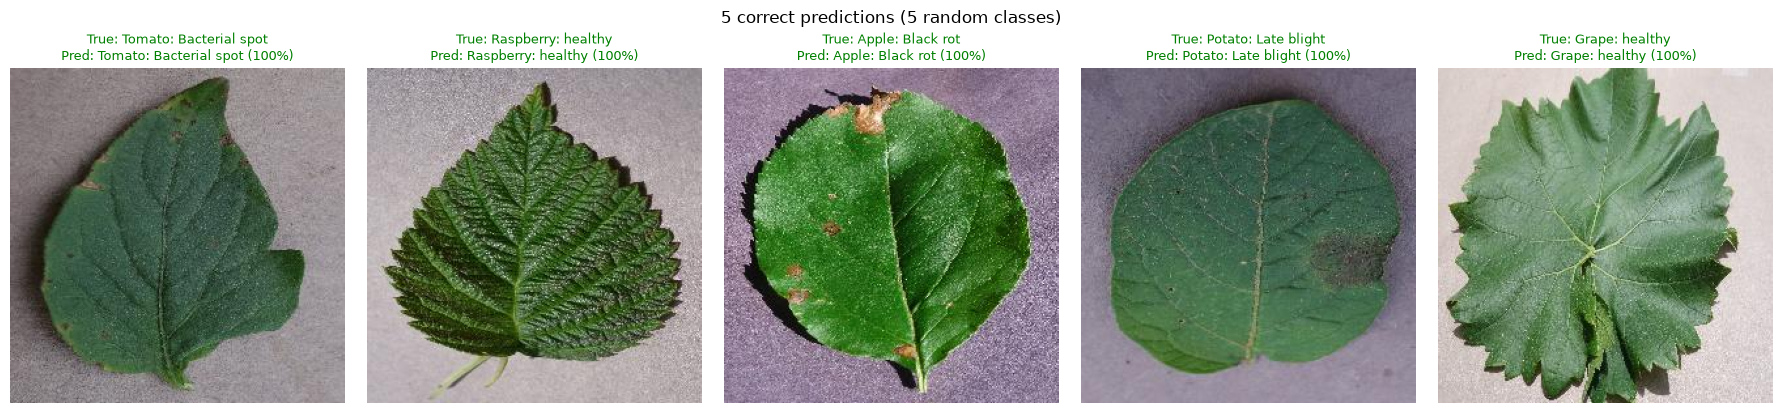

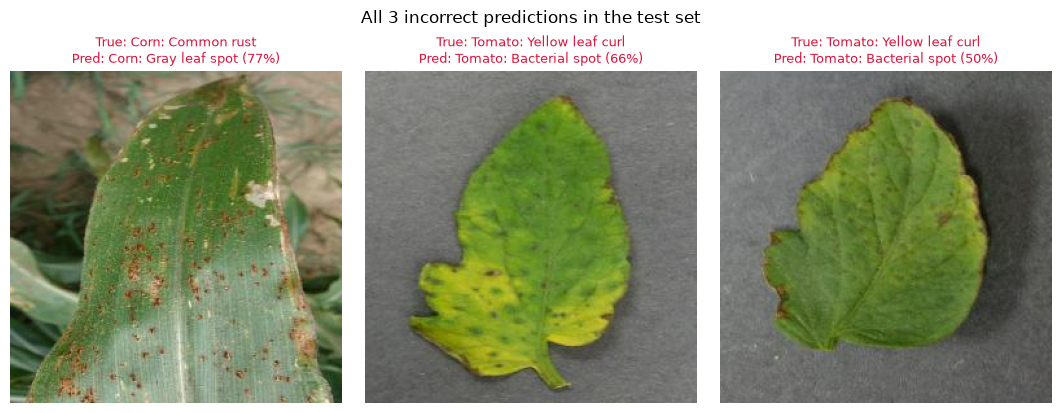

In [18]:
ok_idx, bad_idx = np.where(preds == labels)[0], np.where(preds != labels)[0]
rng = np.random.RandomState(SEED)
show_ok = [rng.choice(ok_idx[labels[ok_idx] == k]) for k in rng.choice(K, 5, replace=False)]  # 5 different classes
show_bad = bad_idx[np.argsort(-conf[bad_idx])][:5]        # most confident mistakes first

def grid(indices, title, color):
    fig, ax = plt.subplots(1, len(indices), figsize=(3.6 * len(indices), 4), squeeze=False)
    for a, i in zip(ax[0], indices):
        a.imshow(Image.open(test_df.path[i]).convert('RGB')); a.axis('off')
        a.set_title(f'True: {short[labels[i]]}\nPred: {short[preds[i]]} ({conf[i]:.0%})', fontsize=9, color=color)
    fig.suptitle(title, y=1.02); plt.tight_layout(); plt.show()

grid(show_ok, '5 correct predictions (5 random classes)', 'green')
grid(show_bad, f'All {len(bad_idx)} incorrect predictions in the test set' if len(bad_idx) <= 5
     else '5 most confident incorrect predictions', 'crimson')

In [19]:
right = conf[preds == labels]
print(f'confidence of correct predictions: median {np.median(right):.4f}, '
      f'{(right < 0.8).sum()} of {len(right)} below 80%')
print('confidence of the wrong predictions:', np.round(np.sort(conf[preds != labels])[::-1], 2))

confidence of correct predictions: median 1.0000, 3 of 1950 below 80%
confidence of the wrong predictions: [0.77 0.66 0.5 ]


### Error analysis
Only **3 of 1,953** test images are misclassified, so all of them are shown above (fewer than the 5 the brief asks for).
- **Corn common rust → gray leaf spot (77%).** This is the only image in the grids taken *in the field*, with soil
  and grass behind the leaf, while the other common-rust images have a black background. It is exactly the
  risk described in insight 3: the model has seen almost no real-world backgrounds.
- **Tomato yellow leaf curl virus → bacterial spot (66% and 50%).** Both leaves show small dark spots that look
  like bacterial spot. Both mistakes stay within the same crop.

**All three mistakes have low confidence (50–77%)**, while correct predictions have a median confidence of 100%.
A simple rule of *"below 80% confidence, ask the farmer for another photo"* would have caught all 3 errors
and affected only 3 of 1,950 correct predictions.

### Business recommendation

**Deploy MobileNetV3-Small in Syngenta's farmer app.** On the held-out test set it ties for the best result
(99.8% accuracy, 0.998 macro-F1, 3 errors in 1,953 images) with RegNetX-400MF, but at **6.2 MB it is 3.3×
smaller** (1.5 M vs 5.1 M parameters). That matters more on a farm than on a server: farmers often download apps
over slow rural connections and need diagnosis to work **offline in the field** on low-cost Android phones.
Its 35 ms per image on one CPU thread is far below what a user notices, and the architecture was designed for
mobile chips, so it converts directly to TensorFlow Lite / Core ML (or ONNX, as in the demo below), and int8
quantisation could make it about 4× smaller again. RegNet is slightly faster on a server CPU but brings no
accuracy gain for the larger download; ResNet18 is 7× larger *and* less accurate; the small CNN is the
smallest but makes about 40× more errors (125 vs 3 on the test set, 0.927 F1), which is not acceptable when a wrong diagnosis means the wrong
crop protection product. Before launch, the model must be validated on **real field photos**, because
PlantVillage images are lab photos; the app should use the 80% confidence threshold above to ask for a
retake instead of showing an uncertain diagnosis.

# Part 4 — Deployment (bonus)

Instead of a Gradio/Streamlit prototype, the chosen model is deployed as a public web app and API:

- **Live demo:** https://crop-disease-classifier.vercel.app (upload a photo or click one of the sample test images)
- **API:** `curl -F "file=@leaf.jpg" https://crop-disease-classifier.vercel.app/api/predict`
- The PyTorch weights are exported to **ONNX** (`export_onnx.py`), so the server only needs `onnxruntime`
  instead of the full PyTorch install. The ONNX model gives the same outputs as PyTorch (max difference 5e-6).
  The same ONNX file could run on-device in a mobile app.
- Code: `app.py` (FastAPI) and `public/index.html`.

# Limitations and next steps
1. **Field validation:** collect a few hundred real farm photos per crop and measure accuracy on them; expect
   it to be lower than 99.8%. Fine-tune on field photos, and add background augmentation (random backgrounds,
   colour jitter, blur) so the model cannot rely on the lab background.
2. **All 38 classes:** extend from 12 to all PlantVillage classes, plus more crops relevant to Syngenta's markets.
3. **"Not a leaf / unknown" handling:** the model always picks one of its 12 classes. Add the confidence
   threshold and an out-of-distribution check.
4. **On-device app:** quantise to int8 and benchmark on a real low-end Android phone.
5. **From diagnosis to action:** link each disease to recommended crop protection products and agronomic advice.